# Numerical Methods for Solving Nonlinear Equations in Python

### Learning Outcomes
- Implement the Bisection Method in Python
- Implement the Newton-Raphson Method in Python
- Apply stopping criteria
- Compute relative approximate and true errors
- Compare convergence rates

## 1- Bisection Method and Newton-Raphson Method

**Example Equation:** $f(x)=x^3-x-2=0$




## Define the Function
The root of $f(x)=x^3-x-2$ lies in [1,2] because f(1)<0 and f(2)>0.

In [14]:
# Import NumPy library for numerical calculations
import numpy as np
# Import Pandas library for creating and displaying tables
import pandas as pd
# Import Matplotlib library for plotting graphs
import matplotlib.pyplot as plt


In [15]:
# Define the nonlinear function

# f(x) = x³ - x - 2

def f(x):
    return x**3 - x - 2
# ---------------------------------------------------------
# Define the derivative of f(x)
# f'(x) = 3x² - 1
# The derivative is required when using the Newton-Raphson Method.
# ---------------------------------------------------------
def df(x):
    return 3 * x**2 - 1
# ---------------------------------------------------------
# True root of the equation. This value is used only for calculating the True Relative Error (Et).
# It is NOT used by either the Bisection Method or Newton-Raphson Method during the root-finding process.
# ---------------------------------------------------------
true_root = 1.52138

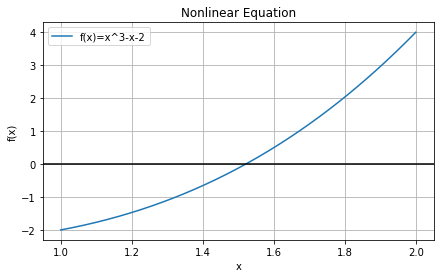

In [16]:
# ---------------------------------------------------------
# Generate 400 equally spaced points between x = 1 and x = 2
# These points will be used to draw the function smoothly.
# ---------------------------------------------------------
x = np.linspace(1, 2, 400)

# ---------------------------------------------------------
# Create a new figure
# figsize = (width, height) in inches
# ---------------------------------------------------------
plt.figure(figsize=(7, 4))

# Plot the nonlinear function f(x) versus x
# Add a label to be displayed in the legend.
# ---------------------------------------------------------
plt.plot(x, f(x), label="f(x)=x^3-x-2")

# Draw the x-axis (y = 0)
# The root occurs where the function crosses this line.
# ---------------------------------------------------------
plt.axhline(0, color="black")

# Display grid lines to make the graph easier to read.
# ---------------------------------------------------------
plt.grid(True)

# Label the horizontal axis.
# ---------------------------------------------------------
plt.xlabel("x")

# Label the vertical axis.
# ---------------------------------------------------------
plt.ylabel("f(x)")

# Add a title to the graph.
# ---------------------------------------------------------
plt.title("Nonlinear Equation")

# Display the legend containing the function label.
# ---------------------------------------------------------
plt.legend()

# Show the graph.
# ---------------------------------------------------------
plt.show()

## Stopping Criteria
Stop when either:

1. $|f(x_i)|<10^{-6}$
2. $\varepsilon_a<0.001\%$

Relative approximate error:

$\varepsilon_a=|((x_i-x_{i-1})/x_i)|\times100$

Relative true error:

$\varepsilon_t=|((x_t-x_i)/x_t)|\times100$

In [17]:

def bisection(f, a, b, xt=None, tol=1e-6, max_iter=100):

    # --------------------------------------------------
    # Step 0: Verify sign change condition
    # A root exists in [a,b] only if f(a) and f(b)
    # have opposite signs.
    # --------------------------------------------------
    if f(a) * f(b) > 0:
        raise ValueError(
            "Invalid interval: f(a) and f(b) must have opposite signs."
        )

    # Store iteration results
    data = []

    # Previous midpoint
    xm_old = None

    # Iteration loop
    for i in range(1, max_iter + 1):

        # Step 1: Compute midpoint
        xm = (a + b) / 2

        # Step 2: Evaluate function
        fxm = f(xm)

        # Step 3: Approximate relative error
        if xm_old is None:
            ea = None
        else:
            ea = abs((xm - xm_old) / xm) * 100

        # Step 4: True relative error
        if xt is None:
            et = None
        else:
            et = abs((xt - xm) / xt) * 100

        # Step 5: Store results
        data.append([
            i, a, b, xm, fxm, ea, et
        ])

        # Step 6: Check exact root
        if fxm == 0:
            print("Exact root found.")
            break

        # Step 7: Check stopping criterion based on function value
        if abs(fxm) < tol:
            print("Stopping criterion |f(xm)| < tol satisfied.")
            break

        # Step 8: Check stopping criterion based on Ea
        if ea is not None and ea < 0.001:
            print("Stopping criterion Ea < 0.001% satisfied.")
            break

        # Step 9: Sign test
        # Root lies in [a, xm]
        if f(a) * fxm < 0:
            b = xm

        # Root lies in [xm, b]
        else:
            a = xm

        # Update midpoint
        xm_old = xm

    columns = [
        "Iter",
        "a",
        "b",
        "xm",
        "f(xm)",
        "Ea (%)",
        "Et (%)"
    ]

    return xm, pd.DataFrame(data, columns=columns)

In [18]:
root_bis,bis_table=bisection(f,1,2,xt=true_root)
print("Bisection Root =",root_bis)
print("\nBisection Results")
display(bis_table)

Stopping criterion Ea < 0.001% satisfied.
Bisection Root = 1.5213851928710938

Bisection Results


,Iter,a,b,xm,f(xm),Ea (%),Et (%)
0,1,1.000000,2.000000,1.500000,-0.125000,NaN,1.405303
1,2,1.500000,2.000000,1.750000,1.609375,14.285714,15.027146
2,3,1.500000,1.750000,1.625000,0.666016,7.692308,6.810922
3,4,1.500000,1.625000,1.562500,0.252197,4.000000,2.702809
4,5,1.500000,1.562500,1.531250,0.059113,2.040816,0.648753
5,6,1.500000,1.531250,1.515625,-0.034054,1.030928,0.378275
6,7,1.515625,1.531250,1.523438,0.012250,0.512821,0.135239
7,8,1.515625,1.523438,1.519531,-0.010971,0.257069,0.121518
8,9,1.519531,1.523438,1.521484,0.000622,0.128370,0.006861
9,10,1.519531,1.521484,1.520508,-0.005179,0.064226,0.057329


In [19]:
def newton(f, df, x0, xt=None, tol=1e-6, max_iter=100):

    # Create a list to store iteration results
    data = []

    # -----------------------------------------------------
    # Start the iteration process
    # -----------------------------------------------------
    for i in range(1, max_iter + 1):

        # Step 1:
        # Evaluate the function at the current estimate
        fx = f(x0)

        # Step 2:
        # Calculate the approximate relative error Ea (%)
        if i == 1:
            ea = None
        else:
            ea = abs((x0 - x_old) / x0) * 100

        # Step 3:
        # Calculate the true relative error Et (%)
        if xt is None:
            et = None
        else:
            et = abs((xt - x0) / xt) * 100

        # Step 4:
        # Store the iteration results
        data.append([i, x0, fx, ea, et])

        # Step 5:
        # Check stopping criterion based on function value
        if abs(fx) < tol:
            break

        # Step 6:
        # Check stopping criterion based on approximate error
        if ea is not None and ea < 0.001:
            break

        # Step 7:
        # Evaluate derivative at current point
        dfx = df(x0)

        # Check if derivative is zero (or very close to zero)
        if abs(dfx) < 1e-12:
            raise ValueError(
                f"Newton-Raphson failed at iteration {i}: "
                f"f'(x) = 0 at x = {x0}"
            )

        # Step 8:
        # Save current approximation
        x_old = x0

        # Apply Newton-Raphson formula
        x0 = x0 - fx / dfx

    # Step 9:
    # Define column names
    cols = ["Iter", "x", "f(x)", "Ea(%)", "Et(%)"]

    # Step 10:
    # Return root estimate and iteration table
    return x0, pd.DataFrame(data, columns=cols)

In [20]:
root_newton,newton_table=newton(f,df,2,xt=true_root)

print("Newton Root =",root_newton)
print("\nNewton-Raphson Results")
display(newton_table)

Newton Root = 1.521379709733148

Newton-Raphson Results


,Iter,x,f(x),Ea(%),Et(%)
0,1,2.000000,4.000000e+00,NaN,31.459596
1,2,1.636364,7.453043e-01,22.222222,7.557851
2,3,1.530392,5.393892e-02,6.924473,0.592360
3,4,1.521441,3.670959e-04,0.588297,0.004040
4,5,1.521380,1.740686e-08,0.004059,0.000019


# Comparison
Bisection Method: x≈1.521385  after 16 iterations.

Newton-Raphson Method: x≈1.521380 after only 4 iterations.

Newton-Raphson converges much faster because it uses derivative information f′(x).

The Bisection Method provided a robust and reliable approach by repeatedly reducing the search interval, while the Newton-Raphson Method converged much faster by utilizing the derivative of the function. 

The results demonstrate that although the Bisection Method guarantees convergence, the Newton-Raphson Method is more computationally efficient when a suitable initial guess and a nonzero derivative are available. 

Python proved to be an effective tool for implementing and analyzing numerical algorithms for solving nonlinear equation

# Excercise 

1- Modify Bisction method function to implement:
- FALSE Position Method
- Modified False Position
2- Modify newton function to implement secant method, modified secant methos

3- Try to slove other functions